<a href="https://colab.research.google.com/github/ProjetosGracie/Sprint4_MLAM_2Semestre/blob/main/Sprint4_MLAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sprint 4 — Classificação Linear com Energia Renovável

**Disciplina:** Machine Learning (MLAM) · **Curso:** Ciência da Computação (2º semestre)

**Objetivo:** prever a classe de produção de energia (`Low`, `Medium` ou `High`) a partir de variáveis climáticas e operacionais, usando um modelo de **classificação linear** (Regressão Logística) e comparando dois cenários de divisão treino/teste (60/40 e 85/15).

**Dataset:** [Renewable Energy Production Dataset (2010–2020)](https://www.kaggle.com/datasets/itsrohithere/renewable-energy-production-dataset-2010-2020/data) — 1000 registros, 11 colunas.

**Roteiro**
1. Análise do dataset: carregamento, encoding, matriz de correlação e seleção de features
2. Definição e aplicação do modelo: Regressão Logística em dois cenários
3. Avaliação de performance: matriz de confusão, métricas e comparação

In [5]:
# Bibliotecas usadas no trabalho
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, classification_report)

warnings.filterwarnings("ignore")   # deixa a saída do notebook mais limpa
sns.set_theme(style="white")        # estilo padrão dos gráficos

SEED = 42                           # mesma semente em todo o trabalho -> resultados reproduzíveis

---
# Etapa 01 — Análise do dataset

## a) Carregamento dos dados

In [6]:
# No Google Colab: faça upload do CSV e use '/content/Renewable_Energy_Data.csv'
# Rodando localmente: deixe o CSV na mesma pasta do notebook
CAMINHO_ARQUIVO = "/content/Renewable_Energy_Data.csv"

df = pd.read_csv(CAMINHO_ARQUIVO)

print(f"Formato do dataset: {df.shape[0]} linhas x {df.shape[1]} colunas")
df.head()

Formato do dataset: 1000 linhas x 11 colunas


,Region,Energy_Source,Temperature_C,Wind_Speed_m_s,Solar_Radiation_kWh_m2,Rainfall_mm,Season,Efficiency_Ratio,Lagged_Production_MWh,Combined_Weather_Index,Energy_Class
0,North,Hydro,13.820937,14.362462,8.834648,3.350827,Winter,125.449109,1419.514155,1.565158,Medium
1,North,Solar,36.972782,19.110474,4.483191,48.767157,Winter,16.325089,4769.329958,0.621331,Low
2,East,Hydro,33.972875,0.364652,5.104325,40.848695,Winter,155.637061,1005.077719,0.156378,High
3,South,Solar,-2.965160,3.915560,6.265925,42.627371,Spring,675.516566,6294.250931,-5.180996,High
4,North,Wind,-3.813486,0.151257,9.263826,46.898262,Spring,626.048277,5550.263638,-3.346412,Medium


In [7]:
# Tipos das colunas e quantidade de valores nulos
df.info()
print("\nValores nulos no total:", df.isnull().sum().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Region                  1000 non-null   object 
 1   Energy_Source           1000 non-null   object 
 2   Temperature_C           1000 non-null   float64
 3   Wind_Speed_m_s          1000 non-null   float64
 4   Solar_Radiation_kWh_m2  1000 non-null   float64
 5   Rainfall_mm             1000 non-null   float64
 6   Season                  1000 non-null   object 
 7   Efficiency_Ratio        1000 non-null   float64
 8   Lagged_Production_MWh   1000 non-null   float64
 9   Combined_Weather_Index  1000 non-null   float64
 10  Energy_Class            1000 non-null   object 
dtypes: float64(7), object(4)
memory usage: 86.1+ KB

Valores nulos no total: 0


Energy_Class
High      486
Medium    336
Low       178
Name: count, dtype: int64


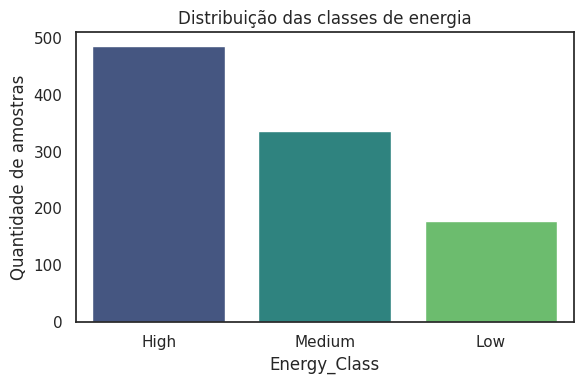

In [8]:
# Distribuição da variável-alvo (importante para saber se as classes estão balanceadas)
contagem = df["Energy_Class"].value_counts()
print(contagem)

plt.figure(figsize=(6, 4))
sns.barplot(x=contagem.index, y=contagem.values, hue=contagem.index, palette="viridis", legend=False)
plt.title("Distribuição das classes de energia")
plt.xlabel("Energy_Class")
plt.ylabel("Quantidade de amostras")
plt.tight_layout()
plt.show()

As classes **não são perfeitamente balanceadas**: `High` tem quase metade das amostras (48,6%). Isso significa que um "modelo bobo" que sempre responde `High` já acertaria ~48,6% — esse é o nosso **ponto de referência** para saber se o modelo realmente aprendeu algo.

## b) Encoding da variável-alvo



In [9]:
# Mapeamento manual respeitando a ordem natural das classes
mapa_classes = {"Low": 0, "Medium": 1, "High": 2}
df["Energy_Class_Encoded"] = df["Energy_Class"].map(mapa_classes)

# Conferindo se o encoding ficou correto
df[["Energy_Class", "Energy_Class_Encoded"]].drop_duplicates().sort_values("Energy_Class_Encoded")

,Energy_Class,Energy_Class_Encoded
1,Low,0
0,Medium,1
2,High,2


## c) Matriz de correlação

Usamos apenas as colunas numéricas (as 7 features + `Energy_Class_Encoded`). As colunas de texto (`Region`, `Energy_Source`, `Season`) não entram na correlação de Pearson.

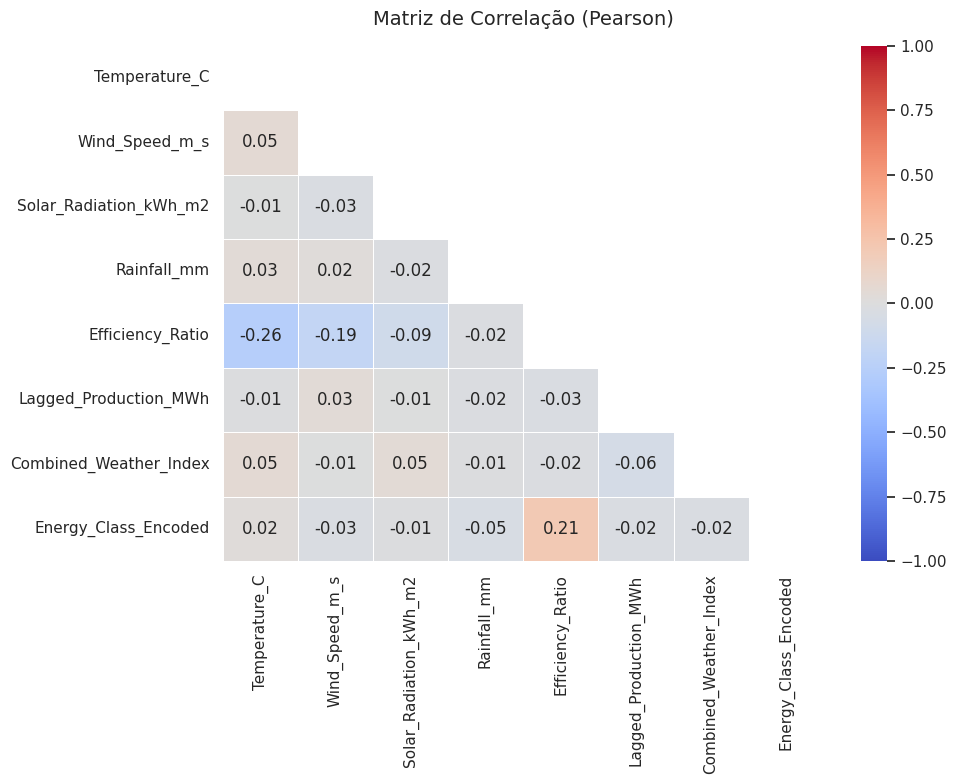

In [10]:
FEATURES = ["Temperature_C", "Wind_Speed_m_s", "Solar_Radiation_kWh_m2", "Rainfall_mm",
            "Efficiency_Ratio", "Lagged_Production_MWh", "Combined_Weather_Index"]

matriz_correlacao = df[FEATURES + ["Energy_Class_Encoded"]].corr()

# Máscara para mostrar só metade do mapa (a matriz é simétrica)
mascara = np.triu(np.ones_like(matriz_correlacao, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(matriz_correlacao, mask=mascara, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matriz de Correlação (Pearson)", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

In [11]:
# Correlação de cada feature com a variável-alvo, ordenada pela força (valor absoluto)
corr_alvo = matriz_correlacao["Energy_Class_Encoded"].drop("Energy_Class_Encoded")
corr_alvo = corr_alvo.sort_values(key=abs, ascending=False)
print(corr_alvo.round(3))

# Maior correlação (em módulo) entre duas FEATURES diferentes
corr_features = matriz_correlacao.loc[FEATURES, FEATURES].abs()
corr_features = corr_features.where(~np.eye(len(FEATURES), dtype=bool), 0)  # zera a diagonal (feature x ela mesma)
print(f"\nMaior correlação entre features: {corr_features.max().max():.2f}")

Efficiency_Ratio          0.211
Rainfall_mm              -0.046
Wind_Speed_m_s           -0.027
Combined_Weather_Index   -0.025
Lagged_Production_MWh    -0.024
Temperature_C             0.018
Solar_Radiation_kWh_m2   -0.008
Name: Energy_Class_Encoded, dtype: float64

Maior correlação entre features: 0.26


## d) Usar um subconjunto de features ou todas?

**O que a matriz mostra:**

- **Correlação feature × alvo:** todas são fracas. A maior é `Efficiency_Ratio` (r ≈ +0,21); as demais ficam abaixo de |0,05|, praticamente zero.
- **Correlação entre features:** a maior é ≈ 0,26 (entre `Temperature_C` e `Efficiency_Ratio`). Não há pares fortemente correlacionados, ou seja, **não existe multicolinearidade/redundância** que justifique remover alguma variável.

**Decisão:** vou usar **todas as 7 features numéricas**. Justificativas técnicas:

1. **Sem redundância:** o principal motivo para cortar features seria remover variáveis muito correlacionadas entre si (que carregam a mesma informação). Isso não acontece aqui.
2. **Pearson mede só relação linear e individual:** uma correlação baixa não prova que a feature é inútil. Ela pode ajudar combinada com as outras, e a Regressão Logística usa todas ao mesmo tempo. Além disso, `Efficiency_Ratio` e `Combined_Weather_Index` têm *outliers* muito grandes, o que também enfraquece o coeficiente de Pearson.
3. **Poucas features (7):** o custo de manter todas é baixo e o risco de *overfitting* é pequeno com 1000 amostras.

Para não ficar só na teoria, a célula abaixo **testa na prática** (validação cruzada de 5 partes) se um subconjunto seria melhor.

In [12]:
# Comparando: todas as features x subconjuntos (validação cruzada estratificada com 5 partes)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
y_todos = df["Energy_Class_Encoded"]

opcoes = {
    "Todas (7 features)": FEATURES,
    "Top 3 por correlação": ["Efficiency_Ratio", "Rainfall_mm", "Wind_Speed_m_s"],
    "Só Efficiency_Ratio": ["Efficiency_Ratio"],
}

linhas = []
for nome, colunas in opcoes.items():
    # Pipeline = padroniza e depois classifica (o scaler é reajustado dentro de cada fold)
    pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    notas = cross_val_score(pipeline, df[colunas], y_todos, cv=cv, scoring="accuracy")
    linhas.append({"Conjunto de features": nome, "Qtd": len(colunas),
                   "Acurácia média": notas.mean(), "Desvio padrão": notas.std()})

pd.DataFrame(linhas).round(3)

,Conjunto de features,Qtd,Acurácia média,Desvio padrão
0,Todas (7 features),7,0.799,0.032
1,Top 3 por correlação,3,0.742,0.031
2,Só Efficiency_Ratio,1,0.765,0.019


**Resultado do teste:** usar todas as features dá a melhor acurácia média (≈ 0,80), contra ≈ 0,74 a 0,77 dos subconjuntos. Isso confirma a decisão: **manter as 7 features**.

> **Observação:** `Efficiency_Ratio` é claramente a variável mais importante, mas sozinha não basta — as outras ainda contribuem com ganho de acurácia.

---
# Etapa 02 — Definição e aplicação do modelo

## a) Modelo escolhido: Regressão Logística (`LogisticRegression`)

Pesquisando na documentação do scikit-learn, a **Regressão Logística** é um classificador linear simples, rápido de treinar e fácil de interpretar. Apesar do nome "regressão", ela é usada para **classificação**. Como temos 3 classes, ela é usada na versão **multinomial** (softmax), que é o comportamento padrão do scikit-learn atual.

## b) Por que ela é considerada linear?

Para cada classe $k$, o modelo calcula um **score linear** com as features $x$:

$$z_k = w_k \cdot x + b_k$$

e depois transforma os scores em probabilidades com a função softmax. A classe prevista é a de maior probabilidade (maior $z_k$).

A **fronteira de decisão** entre duas classes $i$ e $j$ é o conjunto de pontos onde elas empatam, ou seja, $z_i = z_j$:

$$(w_i - w_j) \cdot x + (b_i - b_j) = 0$$

Essa é a equação de um **hiperplano** (uma reta em 2D, um plano em 3D...). Como a fronteira é uma combinação linear das features, o modelo é **linear**. A função softmax/sigmoide só converte o score em probabilidade; ela **não curva a fronteira**.

**Consequência prática:** se as classes não puderem ser separadas por hiperplanos, o modelo vai errar nas regiões de sobreposição — o que veremos nos erros entre classes vizinhas na Etapa 03.

## c) e d) Treinamento nos dois cenários

Para a comparação ser justa, tudo é igual entre os cenários, **exceto o tamanho do teste**: mesmas features, mesmo modelo e hiperparâmetros, mesma semente (`random_state=42`) e divisão **estratificada** (mantém a proporção das classes no treino e no teste).

Também padronizo as features com `StandardScaler` (média 0, desvio 1), pois as escalas são muito diferentes (ex.: `Lagged_Production_MWh` vai até ~10 000 e `Solar_Radiation_kWh_m2` até ~10). O scaler é **ajustado só com os dados de treino** para não vazar informação do teste para o modelo (*data leakage*).

In [13]:
X = df[FEATURES]
y = df["Energy_Class_Encoded"]
NOMES_CLASSES = ["Low", "Medium", "High"]   # na ordem do encoding (0, 1, 2)


def treinar_e_prever(tamanho_teste):
    """Divide os dados, padroniza, treina a Regressão Logística e prevê o teste."""
    X_treino, X_teste, y_treino, y_teste = train_test_split(
        X, y, test_size=tamanho_teste, random_state=SEED, stratify=y
    )

    # O scaler aprende média/desvio SOMENTE no treino
    escalador = StandardScaler()
    X_treino_esc = escalador.fit_transform(X_treino)
    X_teste_esc = escalador.transform(X_teste)

    modelo = LogisticRegression(max_iter=1000, random_state=SEED)
    modelo.fit(X_treino_esc, y_treino)

    y_pred = modelo.predict(X_teste_esc)
    return modelo, y_teste, y_pred, len(X_treino), len(X_teste)


# Cenário 1: 60% treino / 40% teste
modelo1, y_teste1, y_pred1, n_treino1, n_teste1 = treinar_e_prever(0.40)
# Cenário 2: 85% treino / 15% teste
modelo2, y_teste2, y_pred2, n_treino2, n_teste2 = treinar_e_prever(0.15)

print(f"Cenário 1 (60/40): {n_treino1} amostras de treino | {n_teste1} amostras de teste")
print(f"Cenário 2 (85/15): {n_treino2} amostras de treino | {n_teste2} amostras de teste")

Cenário 1 (60/40): 600 amostras de treino | 400 amostras de teste
Cenário 2 (85/15): 850 amostras de treino | 150 amostras de teste


In [14]:
# Coeficientes do modelo do Cenário 2 (uma linha por classe): mostra o peso de cada feature
coeficientes = pd.DataFrame(modelo2.coef_, index=NOMES_CLASSES, columns=FEATURES)
coeficientes.round(2)

,Temperature_C,Wind_Speed_m_s,Solar_Radiation_kWh_m2,Rainfall_mm,Efficiency_Ratio,Lagged_Production_MWh,Combined_Weather_Index
Low,-0.62,-0.21,-0.09,-0.01,-8.12,0.04,0.20
Medium,-0.08,-0.07,-0.06,-0.00,0.66,-0.03,-0.14
High,0.70,0.29,0.15,0.01,7.46,-0.01,-0.05


Os coeficientes (com features padronizadas) mostram que `Efficiency_Ratio` tem peso muito maior que as demais, positivo para `High` e negativo para `Low`. Isso combina com a correlação vista na Etapa 01.

---
# Etapa 03 — Avaliação de performance

## a) Matriz de confusão e b) Métricas

Como o problema tem **3 classes**, precisão e recall são calculados por classe e depois combinados pela média **macro** (cada classe pesa igual, o que é mais justo com classes desbalanceadas).

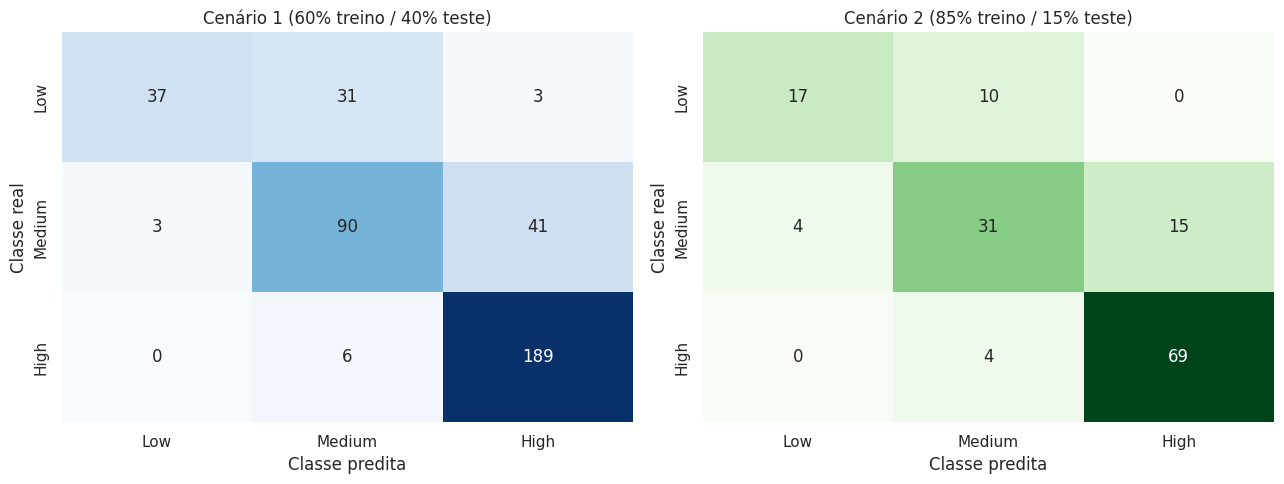

In [15]:
def calcular_metricas(y_real, y_pred):
    """Retorna acurácia, precisão macro e recall macro."""
    return {
        "Acurácia": accuracy_score(y_real, y_pred),
        "Precisão (macro)": precision_score(y_real, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_real, y_pred, average="macro"),
    }


# Matrizes de confusão lado a lado
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
cenarios = [
    ("Cenário 1 (60% treino / 40% teste)", y_teste1, y_pred1, "Blues"),
    ("Cenário 2 (85% treino / 15% teste)", y_teste2, y_pred2, "Greens"),
]
for eixo, (titulo, y_real, y_pred, cor) in zip(eixos, cenarios):
    cm = confusion_matrix(y_real, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap=cor, cbar=False, ax=eixo,
                xticklabels=NOMES_CLASSES, yticklabels=NOMES_CLASSES)
    eixo.set_title(titulo)
    eixo.set_xlabel("Classe predita")
    eixo.set_ylabel("Classe real")
plt.tight_layout()
plt.show()

In [16]:
# Tabela comparativa das métricas
tabela_metricas = pd.DataFrame({
    "Cenário 1 (60/40)": calcular_metricas(y_teste1, y_pred1),
    "Cenário 2 (85/15)": calcular_metricas(y_teste2, y_pred2),
}).T

print("Referência (sempre prever 'High'): acurácia =", round((df['Energy_Class'] == 'High').mean(), 3), "\n")
tabela_metricas.round(4)

Referência (sempre prever 'High'): acurácia = 0.486 



,Acurácia,Precisão (macro),Recall (macro)
Cenário 1 (60/40),0.79,0.8149,0.7207
Cenário 2 (85/15),0.78,0.7733,0.7316


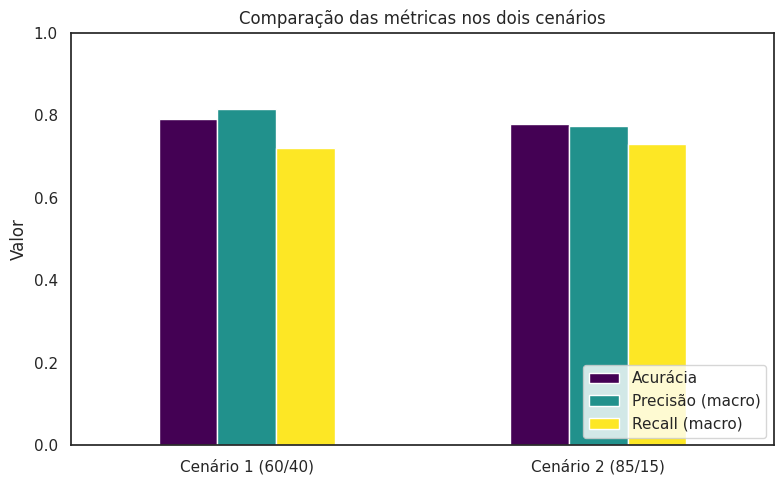

In [17]:
# Gráfico comparando as métricas dos dois cenários
tabela_metricas.plot(kind="bar", figsize=(8, 5), colormap="viridis", rot=0)
plt.title("Comparação das métricas nos dois cenários")
plt.ylabel("Valor")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [18]:
# Relatório por classe (precisão, recall e f1 de cada classe)
for titulo, y_real, y_pred in [("Cenário 1 (60/40)", y_teste1, y_pred1),
                               ("Cenário 2 (85/15)", y_teste2, y_pred2)]:
    print(f"=== {titulo} ===")
    print(classification_report(y_real, y_pred, target_names=NOMES_CLASSES, digits=3))

=== Cenário 1 (60/40) ===
              precision    recall  f1-score   support

         Low      0.925     0.521     0.667        71
      Medium      0.709     0.672     0.690       134
        High      0.811     0.969     0.883       195

    accuracy                          0.790       400
   macro avg      0.815     0.721     0.746       400
weighted avg      0.797     0.790     0.780       400

=== Cenário 2 (85/15) ===
              precision    recall  f1-score   support

         Low      0.810     0.630     0.708        27
      Medium      0.689     0.620     0.653        50
        High      0.821     0.945     0.879        73

    accuracy                          0.780       150
   macro avg      0.773     0.732     0.747       150
weighted avg      0.775     0.780     0.773       150



## c) O desempenho é adequado?

| Métrica | Cenário 1 (60/40) | Cenário 2 (85/15) |
|---|---|---|
| Acurácia | 0,790 | 0,780 |
| Precisão (macro) | 0,815 | 0,773 |
| Recall (macro) | 0,721 | 0,732 |

**Análise:**

- Com 79% de acurácia, o modelo fica **bem acima da referência** (48,6% de sempre prever `High`). Ou seja, ele aprendeu padrões reais dos dados.
- A classe **`High`** é a melhor prevista (recall ≈ 0,95–0,97): quase todas as amostras `High` são identificadas.
- A classe **`Medium`** é a mais difícil (recall ≈ 0,62–0,67) e a **`Low`** tem recall baixo no Cenário 1 (≈ 0,52): muitas amostras `Low` são classificadas como `Medium`, e muitas `Medium` como `High`.
- Os erros acontecem quase sempre entre **classes vizinhas** (Low↔Medium, Medium↔High) e quase nunca entre `Low` e `High`. Isso é esperado: as classes têm uma ordem natural e as fronteiras entre elas são "borradas".

**Conclusão:** o desempenho é **razoável/adequado para um primeiro modelo linear simples**, mas **não é excelente**. Para um uso real em que errar a classe seja custoso, seria interessante testar modelos não lineares (ex.: Árvore de Decisão, Random Forest) ou tratar os *outliers* de `Efficiency_Ratio` e `Combined_Weather_Index`. Como a fronteira da Regressão Logística é linear, ela tem dificuldade em separar a classe do meio (`Medium`).

> **Ponto de atenção:** `Efficiency_Ratio` parece ser calculada a partir da própria produção de energia. Se for o caso, ela pode "entregar" parte da resposta ao modelo (*vazamento de informação*) e inflar um pouco o desempenho. Vale confirmar o significado dessa coluna antes de usar o modelo na prática.

## d) Comparação: 40% de teste × 15% de teste

- A **acurácia** praticamente não mudou (0,790 → 0,780). A diferença de 1 ponto percentual equivale a ~1,5 amostras no teste de 150 — está dentro da variação esperada do acaso.
- A **precisão macro** caiu (0,815 → 0,773) e o **recall macro** subiu levemente (0,721 → 0,732). Essas mudanças são pequenas e, com tão poucas amostras de cada classe no teste, não indicam que um cenário seja de fato melhor que o outro.
- O principal efeito visível está na classe `Low`: no Cenário 1 ela tem recall de 0,52 e no Cenário 2 de 0,63 — mas no Cenário 2 são só **27 amostras** `Low` no teste, então 1 ou 2 acertos mudam muito o número.
- A validação cruzada feita na Etapa 01 (≈ 0,80 ± 0,03) mostra que o modelo tem desempenho estável em torno de 78–80%, coerente com os dois cenários.

## e) Vantagens e limitações do tamanho do conjunto de teste

| | **Teste maior (40%)** | **Teste menor (15%)** |
|---|---|---|
| **Vantagens** | Avaliação **mais confiável**: mais amostras por classe, métricas menos instáveis e intervalo de erro menor. | Sobram **mais dados para treino** (850 em vez de 600), então o modelo aprende melhor. |
| **Limitações** | Menos dados para treino (600), então o modelo pode ficar **um pouco pior** do que poderia (*subajuste* por falta de dados). | Avaliação **menos confiável**: com 150 amostras (e só 27 da classe `Low`), cada erro altera bastante as métricas, que variam muito dependendo de qual sorteio caiu no teste. |

**Resumo:** existe um **trade-off** entre treinar melhor (mais treino) e avaliar melhor (mais teste). Em datasets pequenos como este (1000 linhas), o ideal é usar **validação cruzada**, que usa todos os dados tanto para treino quanto para teste em rodadas diferentes e dá uma estimativa mais estável do desempenho real.

---
# Conclusão geral

- O dataset não tem valores nulos e as features numéricas são pouco correlacionadas entre si, então foram **mantidas as 7**.
- A **Regressão Logística** (modelo linear) atingiu cerca de **78–79% de acurácia** nos dois cenários, bem acima da referência de ~48,6%.
- Os principais erros acontecem entre **classes vizinhas**, principalmente em `Medium`, o que mostra o limite de uma fronteira de decisão linear.
- A escolha entre 60/40 e 85/15 **não mudou de forma relevante** o resultado; o Cenário 1 dá uma avaliação mais confiável, e o Cenário 2 um treino com mais dados.